In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

Відповідність між двома зображеннями 

Fast Library for Approximate Nearest Neighbors (FLANN) - Linear search

In [2]:
# load the images
image1 = cv2.imread('image_l.jpg')
image2 = cv2.imread('image_r.jpg')

In [3]:
#img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
#img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Initiate SIFT detector
sift = cv2.SIFT_create()

In [4]:
# find the keypoints and descriptors with SIFT
keypoint1, descriptors1 = sift.detectAndCompute(image1, None)
keypoint2, descriptors2 = sift.detectAndCompute(image2, None)

In [5]:
# finding nearest match with KNN algorithm
index_params = dict(algorithm=0, trees=20)
search_params = dict(checks=150)   # or pass empty dictionary

In [6]:
# Initialize the FlannBasedMatcher
flann = cv2.FlannBasedMatcher(index_params, search_params)
Matches = flann.knnMatch(descriptors1, descriptors2, k=2)

# Need to draw only good matches, so create a mask
good_matches = [[0, 0] for i in range(len(Matches))]


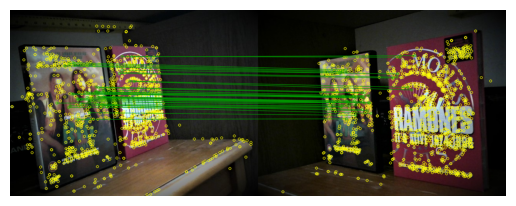

In [19]:
# Ratio Test
for i, (m, n) in enumerate(Matches):
    if m.distance < 0.5*n.distance:
        good_matches[i] = [1, 0]

# Draw the matches using drawMatchesKnn()
Matched = cv2.drawMatchesKnn(image1,
                             keypoint1,
                             image2,
                             keypoint2,
                             Matches,
                             outImg=None,
                             matchColor=(0, 155, 0),
                             singlePointColor=(0, 255, 255),
                             matchesMask=good_matches,
                             flags=0
                             )

# Displaying the image 
cv2.imwrite('Match.jpg', Matched)
plt.axis('off')
plt.imshow(cv2.cvtColor(Matched, cv2.COLOR_BGR2RGB))